# Credit-card fraud: an experimental study
Predict `is_fraud` from transaction attributes in Kaggle Playground S6E11. ROC-AUC measures ranking; average precision adds context for a rare positive class. Neither metric alone establishes business value or a deployment threshold.

This notebook is the complete workflow: **problem/data understanding → validation design → baseline → iterative model development → ensemble and ablation → evaluation and limitations**. Feature analysis, tuning, and model comparison inform one another.

**Two kinds of evidence:** historical results below were transcribed from saved outputs of the preserved original notebook; fresh results are generated by this notebook. The default is a small **SMOKE CHECK**, not a benchmark. Set `SMOKE = False` for full data and training budgets. Optional investigations are explicit switches; there are no hidden kernel dependencies.

Download `train.csv`, `test.csv`, and `sample_submission.csv` from [Kaggle S6E11](https://www.kaggle.com/competitions/playground-series-s6e11/data) into `data/`. See README for installation. Launch from the repository root and run all cells in order.


## 1. Reproducible setup
The default runs five folds on 5,000 stratified rows with 20 boosting rounds to check the workflow quickly. Full mode uses all rows and the recorded training budgets. A fixed seed makes runs repeatable within an environment, but library/platform changes can alter results. Versions and data hashes are printed below. No models, predictions, or submissions are written unless the final export switch is enabled.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
from xgboost import XGBClassifier

SMOKE = True
RUN_BENCHMARK = False       # LightGBM, CatBoost, spline logistic regression
RUN_OPTUNA = False          # exploratory tuning; never silently replaces frozen parameters
RUN_ABLATIONS = False       # removal, interactions, and unfinished digit hypothesis
RUN_IMPORTANCE = False      # permutation importance on one outer validation fold
RUN_ADVERSARIAL = False     # train/test domain discrimination
EXPORT_SUBMISSION = False  # full-mode only; local file, never uploaded
N_TRIALS = 20
SEED, OUTER_SEED, N_FOLDS, JOBS = 42, 123, 5, 1
DATA = Path('data')
RUN_LABEL = 'SMOKE CHECK — not a benchmark' if SMOKE else 'FULL DATA — exploratory validation'
print(RUN_LABEL)
print('Python:', platform.python_version())
for package in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'matplotlib']:
    print(package, metadata.version(package))

def file_hash(path):
    with path.open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()


SMOKE CHECK — not a benchmark
Python: 3.14.7
numpy 2.5.5
pandas 3.1.1
scikit-learn 1.9.1
xgboost 3.4.1
matplotlib 3.11.2


## 2. Understand and check the data
Keep `id` for alignment only; never train on it. Validate the binary target before conversion. Report missingness and duplicate feature/label rows before modeling. The local full training file contains 699,960 rows, 24 predictors and 11,689 fraud labels (about 1.67%). It has no missing values or duplicate feature/label rows. These are file observations, not assumptions enforced for every future download.


In [2]:
assert (DATA / 'train.csv').is_file(), 'Download the Kaggle files into data/ first.'
raw = pd.read_csv(DATA / 'train.csv')
assert {'id', 'is_fraud'} <= set(raw.columns)
assert raw['id'].is_unique and raw['id'].notna().all()
assert raw['is_fraud'].notna().all() and set(raw['is_fraud'].unique()) == {0, 1}
print('train SHA-256:', file_hash(DATA / 'train.csv'))
print('Full shape:', raw.shape, '| Fraud rate:', raw.is_fraud.mean())
print('Duplicate feature/label rows:', raw.drop(columns='id').duplicated().sum())
display(raw.isna().sum().rename('missing').to_frame())
display(raw.is_fraud.value_counts().rename_axis('is_fraud').to_frame('count'))
if SMOKE:
    keep, _ = train_test_split(np.arange(len(raw)), train_size=min(5000, len(raw)-2),
                               stratify=raw.is_fraud, random_state=SEED)
    df = raw.iloc[keep].reset_index(drop=True)
else:
    df = raw.reset_index(drop=True)
X = df.drop(columns=['id', 'is_fraud']).copy()
y = df.is_fraud.astype('int8')
assert not {'id', 'is_fraud'} & set(X.columns)
print('Working shape:', X.shape, '|', RUN_LABEL)


train SHA-256: 87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5
Full shape: (699960, 26) | Fraud rate: 0.016699525687182123
Duplicate feature/label rows: 0
Working shape: (5000, 24) | SMOKE CHECK — not a benchmark


,missing
id,0
amount_usd,0
hours_since_last_txn,0
txn_count_last_24h,0
distance_from_home_km,0
card_age_months,0
customer_age,0
account_balance_usd,0
cvv_retry_count,0
velocity_score,0


,count
is_fraud,
0.0,688271
1.0,11689


### Risk and velocity: descriptive analysis
The original analysis showed higher fraud prevalence when both scores were high. Quantile bins here are **descriptive only**, never model inputs. Counts matter: small segments can produce extreme rates. A full-data historical high-risk segment (`risk > 45.1`, `velocity > 28.0`) contained 29,544 transactions and 9.10% fraud; the three transactions with three CVV retries were all fraud, which is too little evidence for a general rule.


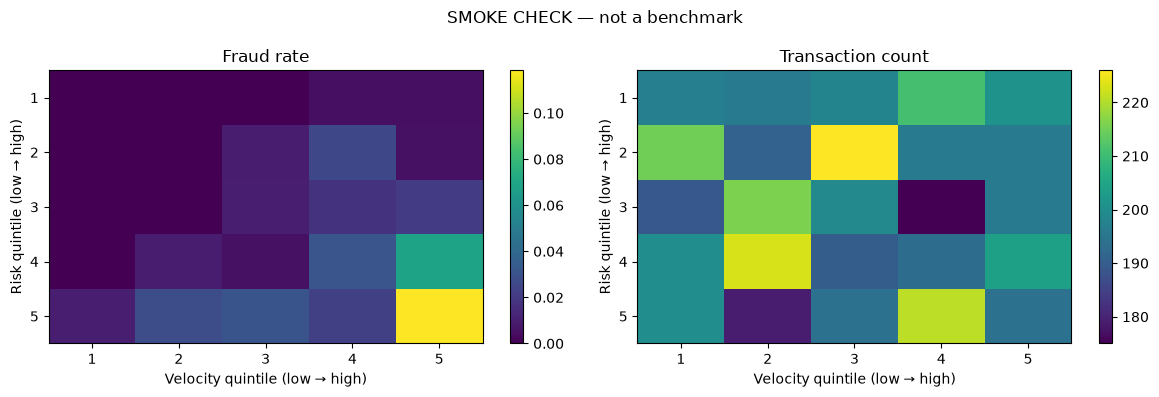

,size,sum,mean
cvv_retry_count,,,
0,174,10,0.057471
1,24,12,0.500000
2,1,1,1.000000


,size,sum,mean
auth_method,,,
3D Secure,52,6,0.115385
Biometric,26,1,0.038462
No Authentication,24,5,0.208333
OTP,49,8,0.163265
PIN,48,3,0.062500


,size,sum,mean
is_new_merchant,,,
False,168,12,0.071429
True,31,11,0.354839


,size,sum,mean
used_vpn,,,
False,189,19,0.100529
True,10,4,0.400000


,size,sum,mean
ip_country_mismatch,,,
False,193,18,0.093264
True,6,5,0.833333


In [3]:
analysis = X.assign(actual=y.to_numpy())
analysis['risk_group'] = pd.qcut(analysis.merchant_risk_score, 5, duplicates='drop')
analysis['velocity_group'] = pd.qcut(analysis.velocity_score, 5, duplicates='drop')
groups = ['risk_group', 'velocity_group']
rates = analysis.groupby(groups, observed=True).actual.mean().unstack()
counts = analysis.groupby(groups, observed=True).actual.size().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, title in zip(axes, [rates, counts], ['Fraud rate', 'Transaction count']):
    im = ax.imshow(values, aspect='auto', cmap='viridis')
    ax.set(title=title, xlabel='Velocity quintile (low → high)', ylabel='Risk quintile (low → high)')
    ax.set_xticks(range(len(values.columns)), range(1, len(values.columns)+1))
    ax.set_yticks(range(len(values)), range(1, len(values)+1))
    fig.colorbar(im, ax=ax)
fig.suptitle(RUN_LABEL); plt.tight_layout(); plt.show()
high_risk = analysis[(analysis.merchant_risk_score > 45.1) & (analysis.velocity_score > 28)]
for col in ['cvv_retry_count', 'auth_method', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch']:
    display(high_risk.groupby(col, observed=True).actual.agg(['size', 'sum', 'mean']))


## 3. Validation before model selection
Use five shuffled stratified **outer** folds (seed 123). Split each outer training fold again: 85% fitting / 15% early stopping (seed 42). Fit categories only on fitting rows; unknown levels become missing. Outer labels never control stopping. Stopping rows are not refitted into the final fold model. All candidates share exactly the same splits.

The mean of five fold AUCs and the AUC of all pooled out-of-fold (OOF) predictions are different quantities: pooling also compares rankings across folds. Report both, and label fold dispersion as population SD (`ddof=0`), not a confidence interval.

**Selection bias remains:** frozen hyperparameters, feature ideas, depths, and blends were selected through repeated exploration on this dataset. An inner stopping split is not nested hyperparameter selection. Neither historical nor new OOF scores are an untouched final test. Random stratification also does not establish future-time or new-customer generalization.


In [4]:
outer_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=OUTER_SEED)
splits = []
for train_idx, val_idx in outer_cv.split(X, y):
    fit_idx, stop_idx = train_test_split(train_idx, test_size=0.15,
                                        stratify=y.iloc[train_idx], random_state=SEED)
    assert not set(fit_idx) & set(stop_idx)
    assert not set(train_idx) & set(val_idx)
    splits.append((fit_idx, stop_idx, val_idx))
assert np.all(np.bincount(np.concatenate([v for _, _, v in splits]), minlength=len(X)) == 1)

def categorical_columns(frame):
    return [c for c in frame if not pd.api.types.is_numeric_dtype(frame[c])]

def prepare_categories(fit, *others):
    frames = [f.copy() for f in (fit, *others)]
    for col in categorical_columns(fit):
        vocabulary = pd.Index(fit[col].astype('object').dropna().unique())
        for frame in frames:
            values = frame[col].astype('object')
            frame[col] = pd.Categorical(values.where(values.isin(vocabulary)), categories=vocabulary)
    return frames

def catboost_frame(frame):
    result = frame.copy()
    for col in categorical_columns(result):
        result[col] = result[col].astype('object').map(
            lambda value: '__MISSING__' if pd.isna(value) else 'value:' + str(value))
    return result

BASELINE = dict(n_estimators=1200, learning_rate=0.05, max_depth=4,
                min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                reg_lambda=1, reg_alpha=0)
# Frozen candidate explicitly recorded in source cell 7; no hidden `study` object.
TUNED = dict(n_estimators=1200, learning_rate=0.0419029183006174, max_depth=3,
             min_child_weight=5, subsample=0.8941260118792025,
             colsample_bytree=0.6311262669743521,
             reg_lambda=0.01734975345695601, reg_alpha=0.003317182150428618)

def make_xgb(params, patience=50):
    params = dict(params)
    if SMOKE:
        params['n_estimators'] = min(params['n_estimators'], 20)
    return XGBClassifier(**params, objective='binary:logistic', eval_metric='auc',
                         early_stopping_rounds=min(patience, 5) if SMOKE else patience,
                         tree_method='hist', enable_categorical=True,
                         random_state=SEED, n_jobs=JOBS)

def run_cv(data, factory, kind='xgb', test_data=None):
    assert len(data) == len(y) and data.index.equals(X.index)
    predictions = np.full(len(y), np.nan)
    coverage = np.zeros(len(y), dtype=int)
    records, test_predictions = [], []
    for fold, (fit_idx, stop_idx, val_idx) in enumerate(splits, 1):
        extra = [] if test_data is None else [test_data]
        frames = prepare_categories(data.iloc[fit_idx], data.iloc[stop_idx], data.iloc[val_idx], *extra)
        if kind == 'cat':
            frames = [catboost_frame(frame) for frame in frames]
        fit, stop, val = frames[:3]
        model = factory()
        if kind == 'lgb':
            from lightgbm import early_stopping
            model.fit(fit, y.iloc[fit_idx], eval_set=[(stop, y.iloc[stop_idx])],
                      eval_metric='auc', callbacks=[early_stopping(5 if SMOKE else 50,
                                                                 first_metric_only=True, verbose=False)])
        elif kind == 'cat':
            model.fit(fit, y.iloc[fit_idx], cat_features=categorical_columns(fit),
                      eval_set=(stop, y.iloc[stop_idx]), early_stopping_rounds=5 if SMOKE else 50,
                      verbose=False)
        elif kind == 'spline':
            # No early stopping: same fitting rows for a controlled comparison.
            model.fit(fit, y.iloc[fit_idx])
        else:
            model.fit(fit, y.iloc[fit_idx], eval_set=[(stop, y.iloc[stop_idx])], verbose=False)
        prob = model.predict_proba(val)[:, 1]
        predictions[val_idx] = prob
        coverage[val_idx] += 1
        records.append({'fold': fold, 'auc': roc_auc_score(y.iloc[val_idx], prob),
                        'average_precision': average_precision_score(y.iloc[val_idx], prob)})
        if test_data is not None:
            test_predictions.append(model.predict_proba(frames[3])[:, 1])
    assert (coverage == 1).all() and np.isfinite(predictions).all()
    assert ((0 <= predictions) & (predictions <= 1)).all()
    scores = pd.DataFrame(records)
    return dict(oof=predictions, folds=scores, mean_auc=scores.auc.mean(),
                sd_auc=scores.auc.std(ddof=0), oof_auc=roc_auc_score(y, predictions),
                average_precision=average_precision_score(y, predictions),
                test=None if test_data is None else np.mean(test_predictions, axis=0))

def summary_table(results):
    return pd.DataFrame({name: {k: result[k] for k in
                         ['mean_auc', 'sd_auc', 'oof_auc', 'average_precision']}
                         for name, result in results.items()}).T


## 4. Baseline, frozen tuned reference, and shallow depth diversity
Start with a constant predictor (ROC-AUC 0.5; average precision equals prevalence), then an untuned depth-4 XGBoost. Compare the recorded tuned candidate, depth 3 / 1,500 rounds / patience 75, and depth 2 / 4,000 rounds / patience 100. They use identical rows and split logic. Smoke mode caps these budgets, so its depth comparisons have no research interpretation.


In [5]:
print('Constant baseline:', roc_auc_score(y, np.zeros(len(y))),
      '| average precision:', average_precision_score(y, np.zeros(len(y))))
results = {}
for name, params, patience in [
    ('Untuned XGBoost', BASELINE, 50),
    ('Tuned XGBoost', TUNED, 50),
    ('Depth 3', {**TUNED, 'max_depth': 3, 'n_estimators': 1500}, 75),
    ('Depth 2 extended', {**TUNED, 'max_depth': 2, 'n_estimators': 4000}, 100),
]:
    results[name] = run_cv(X, lambda p=params, s=patience: make_xgb(p, s))
    print(name, results[name]['oof_auc'], '|', RUN_LABEL)
display(summary_table(results))


Constant baseline: 0.5 | average precision: 0.0166
Untuned XGBoost 0.8884690684642169 | SMOKE CHECK — not a benchmark
Tuned XGBoost 0.8907748137148962 | SMOKE CHECK — not a benchmark
Depth 3 0.8907748137148962 | SMOKE CHECK — not a benchmark
Depth 2 extended 0.8720029599790253 | SMOKE CHECK — not a benchmark


,mean_auc,sd_auc,oof_auc,average_precision
Untuned XGBoost,0.893614,0.014411,0.888469,0.217277
Tuned XGBoost,0.891219,0.025613,0.890775,0.199771
Depth 3,0.891219,0.025613,0.890775,0.199771
Depth 2 extended,0.875566,0.026160,0.872003,0.171783


## 5. Optional model benchmark and tuning
Compare alternative inductive biases: LightGBM, CatBoost, and spline logistic regression. All learned preprocessing is fitted inside the fitting subset. The spline pipeline imputes missing values and ignores unseen one-hot categories. Unlike the historical spline run, which used the entire outer training fold, this controlled comparison uses the same fitting subset as the boosted models.

Optional Optuna tuning uses separate stopping rows but repeatedly scores the same outer folds. Its best value is a **search objective**, not an unbiased performance estimate. It does not replace the frozen reference; a truly independent estimate requires tuning from scratch inside each outer fold or using a previously untouched holdout.


In [6]:
if RUN_BENCHMARK:
    from lightgbm import LGBMClassifier
    from catboost import CatBoostClassifier
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import SplineTransformer, StandardScaler, OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import make_pipeline
    from sklearn.linear_model import LogisticRegression
    for package in ['lightgbm', 'catboost']:
        print(package, metadata.version(package))
    rounds = 20 if SMOKE else 1200
    results['LightGBM'] = run_cv(X, lambda: LGBMClassifier(
        n_estimators=rounds, learning_rate=0.05, num_leaves=15, max_depth=4,
        verbosity=-1, metric='auc', random_state=SEED, n_jobs=JOBS), kind='lgb')
    results['CatBoost'] = run_cv(X, lambda: CatBoostClassifier(
        iterations=rounds, learning_rate=0.05, depth=4, eval_metric='AUC',
        random_seed=SEED, thread_count=JOBS, verbose=False, allow_writing_files=False), kind='cat')
    cats = categorical_columns(X)
    nums = [c for c in X if c not in cats]
    def make_spline():
        pre = ColumnTransformer([
            ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                SplineTransformer(n_knots=5, degree=3, knots='quantile'), StandardScaler()), nums),
            ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
                OneHotEncoder(handle_unknown='ignore')), cats)], sparse_threshold=0)
        return make_pipeline(pre, LogisticRegression(C=0.1, max_iter=1000, solver='lbfgs'))
    results['Spline LR'] = run_cv(X, make_spline, kind='spline')
    display(summary_table(results))
else:
    print('Optional model benchmark skipped.')

if RUN_OPTUNA:
    import optuna
    print('optuna', metadata.version('optuna'))
    def objective(trial):
        params = dict(n_estimators=1200,
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            max_depth=trial.suggest_int('max_depth', 3, 8),
            min_child_weight=trial.suggest_int('min_child_weight', 1, 20),
            subsample=trial.suggest_float('subsample', 0.6, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
            reg_lambda=trial.suggest_float('reg_lambda', 0.01, 100, log=True),
            reg_alpha=trial.suggest_float('reg_alpha', 0.0001, 10, log=True))
        return run_cv(X, lambda: make_xgb(params))['mean_auc']
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
    print('Exploratory search objective:', study.best_value, study.best_params)


Optional model benchmark skipped.


## 6. Ensemble and error analysis
Use the equal-weight depth-2/depth-3 blend specified before this run. Do not optimize weights silently on OOF labels. Inspect correlation, ROC and precision–recall curves, then segment residuals (observed fraud rate minus average predicted probability). These are diagnostics on the development data, not proof of calibration or causal effects. Average precision is reported by its proper name, not trapezoidal PR-AUC.


SMOKE CHECK — not a benchmark
Blend mean fold AUC: 0.8880349649505485 | population SD: 0.023669416828722676
Blend pooled OOF AUC: 0.886201303076859 | average precision: 0.18510798348707466


,Untuned XGBoost,Tuned XGBoost,Depth 3,Depth 2 extended
Untuned XGBoost,1.000000,0.701133,0.701133,0.632903
Tuned XGBoost,0.701133,1.000000,1.000000,0.948362
Depth 3,0.701133,1.000000,1.000000,0.948362
Depth 2 extended,0.632903,0.948362,0.948362,1.000000


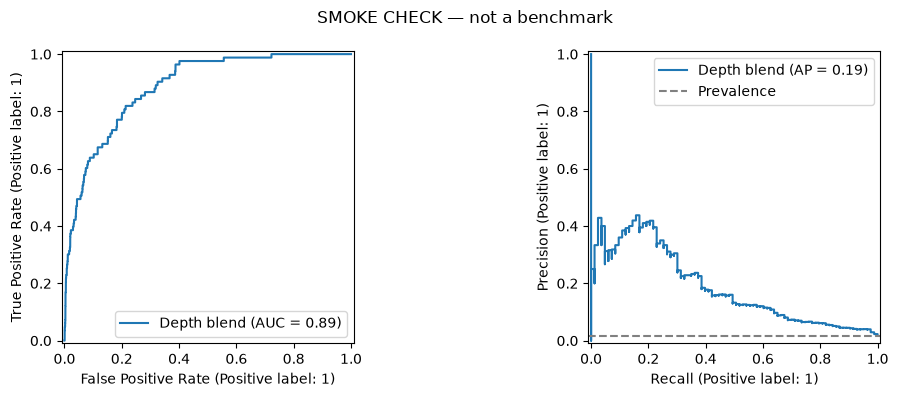

fraud_rate  predicted_rate  count  residual
risk_group     velocity_group                                             
(-0.001, 24.8] (-0.001, 9.4]     0.000000        0.011546    197 -0.011546
               (9.4, 15.7]       0.000000        0.011558    196 -0.011558
               (15.7, 21.4]      0.000000        0.012247    198 -0.012247
               (21.4, 28.2]      0.004739        0.014684    211 -0.009945
               (28.2, 62.8]      0.004975        0.020435    201 -0.015460
(24.8, 31.5]   (-0.001, 9.4]     0.000000        0.010999    215 -0.010999
               (9.4, 15.7]       0.000000        0.011032    191 -0.011032
               (15.7, 21.4]      0.008850        0.012319    226 -0.003470
               (21.4, 28.2]      0.025510        0.015179    196  0.010331
               (28.2, 62.8]      0.005102        0.021643    196 -0.016541
(31.5, 37.0]   (-0.001, 9.4]     0.000000        0.011283    189 -0.011283
               (9.4, 15.7]       0.000000        0.011572    216 -0.011572
               (15.7, 21.4]      0.010050        0.011782    199 -0.001732
               (21.4, 28.2]      0.017143        0.015213    175  0.001930
               (28.2, 62.8]      0.020408        0.020821    196 -0.000412
(37.0, 44.8]   (-0.001, 9.4]     0.000000        0.013292    200 -0.013292
               (9.4, 15.7]       0.008969        0.013100    223 -0.004132
               (15.7, 21.4]      0.005263        0.014081    190 -0.008818
               (21.4, 28.2]      0.031088        0.018285    193  0.012803
               (28.2, 62.8]      0.068627        0.031979    204  0.036648
(44.8, 100.0]  (-0.001, 9.4]     0.010000        0.018330    200 -0.008330
               (9.4, 15.7]       0.027933        0.019070    179  0.008863
               (15.7, 21.4]      0.030928        0.019273    194  0.011655
               (21.4, 28.2]      0.022624        0.021977    221  0.000648
               (28.2, 62.8]      0.118557        0.040074    194  0.078483

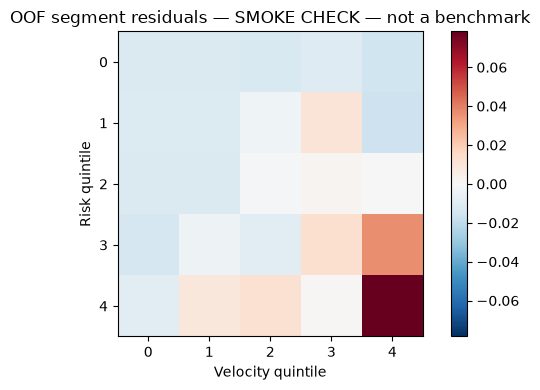

In [7]:
blend = (results['Depth 2 extended']['oof'] + results['Depth 3']['oof']) / 2
blend_folds = np.array([roc_auc_score(y.iloc[v], blend[v]) for _, _, v in splits])
print(RUN_LABEL)
print('Blend mean fold AUC:', blend_folds.mean(), '| population SD:', blend_folds.std(ddof=0))
print('Blend pooled OOF AUC:', roc_auc_score(y, blend),
      '| average precision:', average_precision_score(y, blend))
display(pd.DataFrame({name: result['oof'] for name, result in results.items()}).corr())
if RUN_BENCHMARK:
    three_model_blend = np.mean([results[name]['oof'] for name in ['Tuned XGBoost', 'LightGBM', 'CatBoost']], axis=0)
    print('Three-family blend OOF AUC:', roc_auc_score(y, three_model_blend))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y, blend, ax=axes[0], name='Depth blend')
PrecisionRecallDisplay.from_predictions(y, blend, ax=axes[1], name='Depth blend')
axes[1].axhline(y.mean(), color='gray', linestyle='--', label='Prevalence')
axes[1].legend(); fig.suptitle(RUN_LABEL); plt.tight_layout(); plt.show()
analysis['predicted'] = results['Tuned XGBoost']['oof']
segments = analysis.groupby(groups, observed=True).agg(
    fraud_rate=('actual', 'mean'), predicted_rate=('predicted', 'mean'), count=('actual', 'size'))
segments['residual'] = segments.fraud_rate - segments.predicted_rate
display(segments)
residuals = segments.residual.unstack()
limit = max(float(np.nanmax(np.abs(residuals))), 1e-6)
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(residuals, cmap='RdBu_r', vmin=-limit, vmax=limit)
ax.set(title='OOF segment residuals — ' + RUN_LABEL, xlabel='Velocity quintile', ylabel='Risk quintile')
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


## 7. Feature hypotheses and paired ablations
Preserve the original investigations: remove risk/velocity, retain only those scores, use the six historically important predictors, test four interaction groups, and inspect digit patterns. The top-six list was selected on this dataset and carries selection bias. Interactions are row-local arithmetic; category vocabularies are still learned separately within each fit split.

Historical ablation showed that risk/velocity are important but insufficient alone. Security interactions gave only +0.000130 mean fold AUC; all interaction groups together reduced performance. Digit histograms existed, but the original evaluation cell was malformed and had no saved score. **Digit features remain an unverified hypothesis**, not a claimed improvement.


In [8]:
def build_features(X, groups=()):
    df = X.copy()

    if "H1" in groups:
        df["risk_x_velocity"] = (
            df["merchant_risk_score"] *
            df["velocity_score"]
        )

        df["risk_x_cvv"] = (
            df["merchant_risk_score"] *
            df["cvv_retry_count"]
        )

        df["velocity_x_cvv"] = (
            df["velocity_score"] *
            df["cvv_retry_count"]
        )

        df["new_merchant_x_risk"] = (
            df["is_new_merchant"].astype(int) *
            df["merchant_risk_score"]
        )

    if "H2" in groups:
        df["auth_x_cvv"] = (
            df["auth_method"].astype(str) + "_" +
            df["cvv_retry_count"].clip(upper=3).astype(str)
        ).astype("category")

        df["auth_x_channel"] = (
            df["auth_method"].astype(str) + "_" +
            df["channel"].astype(str)
        ).astype("category")

    if "H3" in groups:
        balance = df["account_balance_usd"].abs().clip(lower=1)

        df["amount_balance_ratio"] = (
            df["amount_usd"] / balance
        )

        df["log_amount"] = np.log1p(
            df["amount_usd"].clip(lower=0)
        )

        df["amount_x_merchant_risk"] = (
            df["amount_usd"] *
            df["merchant_risk_score"]
        )

    if "H4" in groups:
        security_cols = [
            "used_vpn",
            "ip_country_mismatch",
            "billing_shipping_mismatch",
            "is_foreign_transaction"
        ]

        df["security_flags_count"] = (
            df[security_cols].astype(int).sum(axis=1)
        )

        df["vpn_x_ip_mismatch"] = (
            df["used_vpn"].astype(int) *
            df["ip_country_mismatch"].astype(int)
        )

        df["foreign_x_new_merchant"] = (
            df["is_foreign_transaction"].astype(int) *
            df["is_new_merchant"].astype(int)
        )

    return df


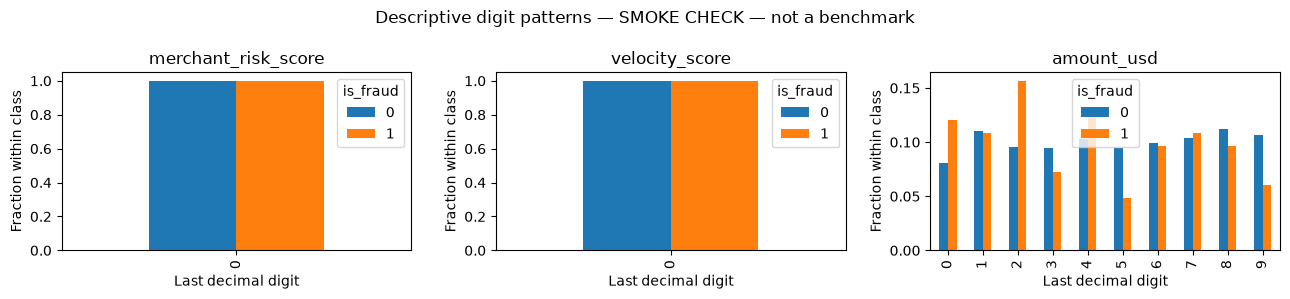

In [9]:
def digit_features(data):
    out = data.copy()
    for col in ['merchant_risk_score', 'velocity_score', 'amount_usd']:
        values = data[col].abs()
        cents = (values * 100).round()
        # Keep missing values; integer digit labels are categorical, not ordinal.
        out[col + '_last_digit'] = (cents % 10).astype('Int64').astype('string')
        out[col + '_last_two'] = (cents % 100).astype('Int64').astype('string')
        out[col + '_rounding_residual'] = values - values.round(1)
    return out

digits = digit_features(X)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col in zip(axes, ['merchant_risk_score', 'velocity_score', 'amount_usd']):
    pd.crosstab(digits[col + '_last_digit'], y, normalize='columns').plot.bar(ax=ax)
    ax.set(title=col, ylabel='Fraction within class', xlabel='Last decimal digit')
fig.suptitle('Descriptive digit patterns — ' + RUN_LABEL); plt.tight_layout(); plt.show()

if RUN_ABLATIONS:
    risk = ['merchant_risk_score', 'velocity_score']
    top6 = ['velocity_score', 'merchant_risk_score', 'cvv_retry_count',
            'auth_method', 'is_new_merchant', 'customer_age']
    ablations = {'Full': results['Tuned XGBoost']}
    feature_sets = {'Without risk/velocity': X.drop(columns=risk),
                    'Only risk/velocity': X[risk], 'Top 6': X[top6]}
    for name, groups_ in {'H1 Risk': ('H1',), 'H2 Auth': ('H2',),
                          'H3 Amount': ('H3',), 'H4 Security': ('H4',),
                          'All interactions': ('H1', 'H2', 'H3', 'H4')}.items():
        feature_sets[name] = build_features(X, groups_)
    for name, data in feature_sets.items():
        ablations[name] = run_cv(data, lambda: make_xgb(TUNED))
    table = summary_table(ablations)
    table['delta_mean_vs_full'] = table.mean_auc - table.loc['Full', 'mean_auc']
    display(table)
    digit_results = {'Baseline depth 2': results['Depth 2 extended']}
    for suffix in ['_last_digit', '_last_two', '_rounding_residual', 'ALL']:
        extra = [c for c in digits if c not in X and (suffix == 'ALL' or c.endswith(suffix))]
        digit_results[suffix] = run_cv(digits[list(X.columns) + extra],
            lambda: make_xgb({**TUNED, 'max_depth': 2, 'n_estimators': 4000}, 100))
    display(summary_table(digit_results))


### Optional permutation importance and adversarial validation
Permutation importance measures a fitted model's reliance on predictors, not causal importance. Correlated variables can hide or redistribute importance. Use one outer validation fold, with separate stopping rows, and report repeat variability.

Adversarial validation predicts whether a row came from train or test. Test labels are never used. A historical AUC of 0.500373 suggests little separation for that model; it does not prove identical distributions or absence of leakage.


In [10]:
if RUN_IMPORTANCE:
    from sklearn.inspection import permutation_importance
    fi, si, vi = splits[0]
    fit, stop, val = prepare_categories(X.iloc[fi], X.iloc[si], X.iloc[vi])
    model = make_xgb(TUNED)
    model.fit(fit, y.iloc[fi], eval_set=[(stop, y.iloc[si])], verbose=False)
    importance = permutation_importance(model, val, y.iloc[vi], scoring='roc_auc',
                                        n_repeats=2 if SMOKE else 5, random_state=SEED, n_jobs=1)
    importance_table = pd.DataFrame({'feature': X.columns, 'mean_auc_drop': importance.importances_mean,
                                     'repeat_sd': importance.importances_std}).sort_values('mean_auc_drop')
    display(importance_table.sort_values('mean_auc_drop', ascending=False))
    importance_table.tail(12).plot.barh(x='feature', y='mean_auc_drop', xerr='repeat_sd', legend=False)
    plt.title('Permutation importance — ' + RUN_LABEL); plt.tight_layout(); plt.show()

if RUN_ADVERSARIAL:
    from lightgbm import LGBMClassifier
    test = pd.read_csv(DATA / 'test.csv')
    assert set(test.columns) == set(raw.columns) - {'is_fraud'}
    train_domain = raw.drop(columns=['id', 'is_fraud'])
    test_domain = test[X.columns]
    if SMOKE:
        train_domain = train_domain.sample(min(2500, len(train_domain)), random_state=SEED)
        test_domain = test_domain.sample(min(2500, len(test_domain)), random_state=SEED)
    domain = pd.concat([train_domain, test_domain], ignore_index=True)
    domain_y = np.r_[np.zeros(len(train_domain)), np.ones(len(test_domain))]
    di, dv = train_test_split(np.arange(len(domain)), test_size=0.25, stratify=domain_y, random_state=SEED)
    dfit, dval = prepare_categories(domain.iloc[di], domain.iloc[dv])
    adv = LGBMClassifier(n_estimators=20 if SMOKE else 300, learning_rate=0.05,
                         num_leaves=15, verbosity=-1, random_state=SEED, n_jobs=JOBS)
    adv.fit(dfit, domain_y[di])
    print('Domain discrimination AUC:', roc_auc_score(domain_y[dv], adv.predict_proba(dval)[:, 1]), RUN_LABEL)


## 8. Historical evidence (not results of this execution)
The following constants were checked against saved outputs of `main_with_stratifiedKFold.ipynb` (zero-based cell numbers below). Original SHA-256: `e81712caaea9f370e00b7dccdfd01565fdcf14cdddf6d5ee1ab81837419f707a`. The source remains untouched locally; the public notebook is self-contained and does not load it.

These outputs establish what was recorded, not a fresh full-data reproduction. Historical depth/ablation cells used globally constructed category vocabularies; the new implementation learns them within fitting rows. Historical tuning also used the scoring fold for stopping. The corrected three-family ensemble used a separate stopping split and fit-only categories. Exact score equality is not promised.

No verified saved output supports the earlier conversational “initial 0.90625” claim. It is omitted. The old hard-coded XGBoost benchmark 0.946670 is not a verified fresh run and is also omitted.


,experiment,mean_fold_auc,pooled_oof_auc,source_cell
0,Tuned XGBoost,0.946910,0.946842,7
1,LightGBM,0.945912,0.945864,7
2,CatBoost,0.946095,0.946087,7
3,Three-family equal blend,NaN,0.946854,7
4,Spline LR,0.944404,0.944389,19
5,Depth 1 / 1500,0.945770,0.945761,21
6,Depth 2 / 1500,0.947078,0.947061,21
7,Depth 3 / 1500,0.947114,0.947083,21
8,Depth 4 / 1500,0.946631,0.946579,21
9,Depth 2+3 / 1500 blend,NaN,0.947220,22


,experiment,mean_fold_auc,source_cell
0,Full,0.946910,10
1,Without risk/velocity,0.923393,10
2,Only risk/velocity,0.817603,10
3,Top 6,0.923875,10
4,H1 Risk,0.946681,13
5,H2 Auth,0.946348,13
6,H3 Amount,0.946919,13
7,H4 Security,0.947040,13
8,All interactions,0.946253,13


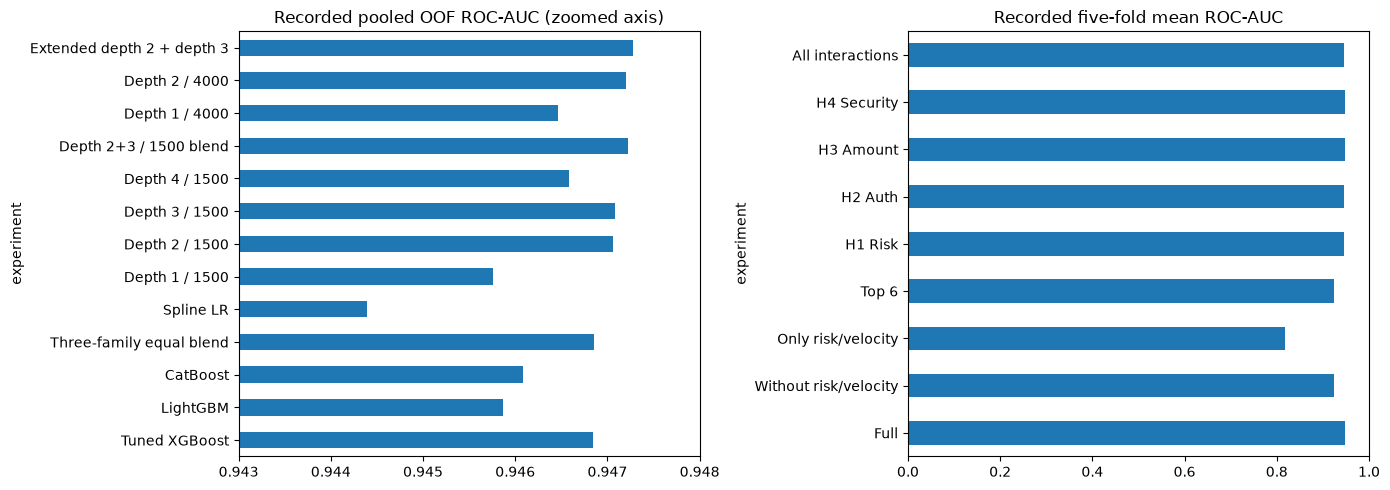

In [11]:
historical = pd.DataFrame([
    ('Tuned XGBoost', .946910, .946842, 7),
    ('LightGBM', .945912, .945864, 7),
    ('CatBoost', .946095, .946087, 7),
    ('Three-family equal blend', np.nan, .946854, 7),
    ('Spline LR', .944404, .944389, 19),
    ('Depth 1 / 1500', .945770, .945761, 21),
    ('Depth 2 / 1500', .947078, .947061, 21),
    ('Depth 3 / 1500', .947114, .947083, 21),
    ('Depth 4 / 1500', .946631, .946579, 21),
    ('Depth 2+3 / 1500 blend', np.nan, .947220, 22),
    ('Depth 1 / 4000', .946500, .946461, 23),
    ('Depth 2 / 4000', .947226, .947196, 23),
    ('Extended depth 2 + depth 3', np.nan, .947278, 24),
], columns=['experiment', 'mean_fold_auc', 'pooled_oof_auc', 'source_cell'])
historical_ablation = pd.DataFrame([
    ('Full', .946910, 10), ('Without risk/velocity', .923393, 10),
    ('Only risk/velocity', .817603, 10), ('Top 6', .923875, 10),
    ('H1 Risk', .946681, 13), ('H2 Auth', .946348, 13),
    ('H3 Amount', .946919, 13), ('H4 Security', .947040, 13),
    ('All interactions', .946253, 13)
], columns=['experiment', 'mean_fold_auc', 'source_cell'])
display(historical); display(historical_ablation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
historical.plot.barh(x='experiment', y='pooled_oof_auc', ax=axes[0], legend=False)
axes[0].set(xlim=(.943, .948), title='Recorded pooled OOF ROC-AUC (zoomed axis)')
historical_ablation.plot.barh(x='experiment', y='mean_fold_auc', ax=axes[1], legend=False)
axes[1].set(xlim=(0, 1), title='Recorded five-fold mean ROC-AUC')
plt.tight_layout(); plt.show()


## 9. Evaluation, limitations, and next steps
- Best saved exploratory OOF AUC: **0.947278**, an equal blend of extended depth 2 and depth 3. Its gain over extended depth 2 is about **0.000082**; no statistical significance is established.
- Three boosting families had correlations around **0.983–0.988** and little ensemble gain. Spline mixing also offered little improvement (best recorded candidate: 90% XGBoost / 10% spline, OOF 0.946857).
- Permutation importance ranked velocity (AUC drop 0.059282) and merchant risk (0.050823) highest in the saved diagnostic; CVV retries and authentication followed. Removal tests show the full set still matters.
- Repeated validation-driven model, feature, and blend selection creates optimism. These are development results, not independent estimates or leaderboard results. Fold SD is descriptive variability; tiny gains are not automatically meaningful.
- No customer ID or absolute transaction time is available for grouped/temporal validation. Verify feature availability at decision time, especially risk, velocity, and scam indicators. A near-chance adversarial AUC cannot establish lack of leakage.
- Review costs, recall at an operational false-positive budget, calibration, and a threshold on separate validation data before any deployment. This notebook makes no production-readiness claim.

A next independent study should lock the protocol and evaluate on an untouched holdout, or perform the complete search within nested outer folds. Do not infer a competition rank from these metrics.


## 10. Optional local submission export
Disabled by default. In full mode this refits both pre-specified shallow candidates across the same folds and averages their test probabilities. Test categories are mapped using each fold's fitting vocabulary. The sample submission controls ID order and schema. Existing output is protected against overwrite. This writes a file only; it does not upload to Kaggle or GitHub.


In [12]:
if EXPORT_SUBMISSION:
    assert not SMOKE, 'Submission export requires full mode.'
    output_path = Path('outputs/submission.csv')
    assert not output_path.exists(), 'Refusing to overwrite an existing submission.'
    test = pd.read_csv(DATA / 'test.csv')
    sample = pd.read_csv(DATA / 'sample_submission.csv')
    assert set(test.columns) == set(raw.columns) - {'is_fraud'}
    assert list(sample.columns) == ['id', 'is_fraud']
    assert test.id.is_unique and sample.id.is_unique
    assert set(test.id) == set(sample.id)
    test_X = test[X.columns]
    p2 = run_cv(X, lambda: make_xgb({**TUNED, 'max_depth': 2, 'n_estimators': 4000}, 100), test_data=test_X)['test']
    p3 = run_cv(X, lambda: make_xgb({**TUNED, 'max_depth': 3, 'n_estimators': 1500}, 75), test_data=test_X)['test']
    probabilities = pd.Series((p2+p3)/2, index=test.id)
    sample['is_fraud'] = sample.id.map(probabilities)
    assert sample.is_fraud.notna().all() and sample.is_fraud.between(0, 1).all()
    output_path.parent.mkdir(exist_ok=True)
    sample.to_csv(output_path, index=False, mode='x')
    print('Saved locally:', output_path)
else:
    print('Submission export disabled.')


Submission export disabled.
